In [4]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA_DIR = Path("../data")

df = pd.read_csv(DATA_DIR / "home_advantage_matches.csv")
data_dict = pd.read_csv(
    DATA_DIR / "data_dictionary_home_advantage.csv"
)

print("Dataset shape:", df.shape)
print("Data dictionary shape:", data_dict.shape)

display(df.head())
display(data_dict.head())

Matplotlib is building the font cache; this may take a moment.


Dataset shape: (50000, 25)
Data dictionary shape: (25, 3)


,match_id,league,elo_home,elo_away,elo_diff,crowd_present,stadium_capacity,attendance_pct,crowd_size,travel_distance_km,...,fouls_away,yellow_home,yellow_away,red_home,red_away,goals_home,goals_away,home_goal_diff,home_result,home_points
0,MCH000000,Serie_A,1255,1507,-252,1,46200,0.557,25700,380.0,...,11,0,3,0,0,1,1,0,draw,1
1,MCH000001,Serie_A,1535,1500,35,1,27400,0.869,23800,420.0,...,14,1,1,0,0,4,2,2,home_win,3
2,MCH000002,Primeira,1736,1370,366,0,61800,0.000,0,16.5,...,13,4,1,0,0,0,2,-2,away_win,0
3,MCH000003,Eredivisie,1484,1476,8,1,30100,0.820,24700,110.0,...,13,2,2,0,0,0,0,0,draw,1
4,MCH000004,EPL,1407,1540,-133,1,55000,0.748,41100,300.0,...,16,1,1,0,0,2,0,2,home_win,3


,column,type,description
0,match_id,string,Unique match id
1,league,string,"Competition (EPL, La_Liga, Serie_A, Bundesliga..."
2,elo_home,int,EARNED: home team strength (Elo-like)
3,elo_away,int,EARNED: away team strength (Elo-like)
4,elo_diff,int,elo_home - elo_away (positive favors home on m...


Loaded the simulated dataset containing 50,000 matches and 25 columns, along with its data dictionary. Inspected the dataset structure, variable types, and sample records.

In [5]:
# Step 2: Data Quality & Schema Validation

print("=== DATA TYPES ===")
display(df.dtypes.to_frame(name="dtype"))

print("\n=== MISSING VALUES ===")
missing = df.isnull().sum()
display(
    pd.DataFrame({
        "missing_count": missing,
        "missing_pct": (missing / len(df) * 100).round(2)
    }).query("missing_count > 0")
)

print("\n=== DUPLICATE ROWS ===")
print("Duplicate rows:", df.duplicated().sum())

print("\n=== DATA DICTIONARY COLUMNS ===")
print(data_dict.columns.tolist())

=== DATA TYPES ===


,dtype
match_id,str
league,str
elo_home,int64
elo_away,int64
elo_diff,int64
crowd_present,int64
stadium_capacity,int64
attendance_pct,float64
crowd_size,int64
travel_distance_km,float64



=== MISSING VALUES ===


,missing_count,missing_pct



=== DUPLICATE ROWS ===
Duplicate rows: 0

=== DATA DICTIONARY COLUMNS ===
['column', 'type', 'description']


No missing values, duplicate records, or duplicate match IDs were found. Data types appeared consistent, so no initial cleaning was required.

,Count,Percentage
home_result,,
home_win,23426,46.85
away_win,14689,29.38
draw,11885,23.77


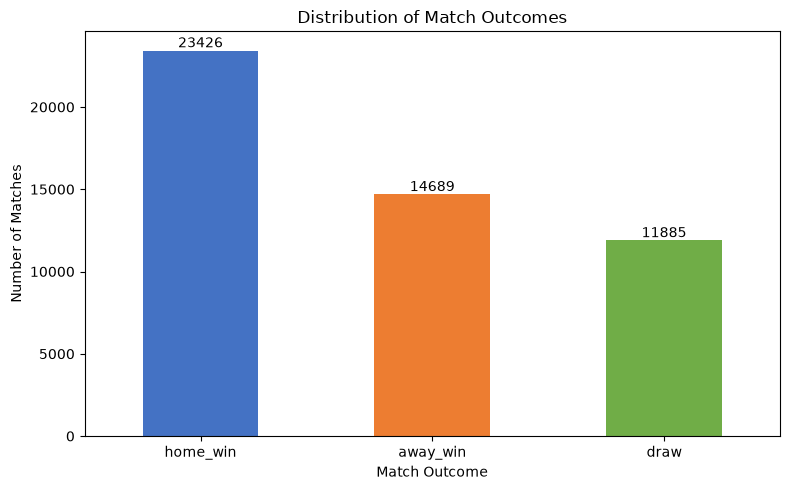

In [6]:
# Step 3: Target Distribution Analysis

target_counts = df["home_result"].value_counts()
target_percentages = (
    df["home_result"].value_counts(normalize=True) * 100
)

target_summary = pd.DataFrame({
    "Count": target_counts,
    "Percentage": target_percentages.round(2)
})

display(target_summary)

# Visualization
ax = target_counts.plot(
    kind="bar",
    figsize=(8, 5),
    title="Distribution of Match Outcomes",
    color=["#4472C4", "#ED7D31", "#70AD47"]
)

ax.set_xlabel("Match Outcome")
ax.set_ylabel("Number of Matches")
ax.bar_label(ax.containers[0])

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Home wins account for 46.85% of matches, followed by away wins (29.38%) and draws (23.77%). This indicates moderate class imbalance and establishes a majority-class baseline of 46.85% accuracy.

In [7]:
# Step 4: Feature Selection

selected_features = [
    "league",
    "elo_home",
    "elo_away",
    "crowd_present",
    "stadium_capacity",
    "attendance_pct",
    "travel_distance_km",
    "timezones_crossed",
    "is_derby",
    "venue_familiarity"
]

target = "home_result"

excluded_features = [
    col for col in df.columns
    if col not in selected_features + [target]
]

print("=== SELECTED FEATURES ===")
for feature in selected_features:
    print(feature)

print("\n=== EXCLUDED FEATURES ===")
for feature in excluded_features:
    print(feature)

print("\nSelected features:", len(selected_features))
print("Excluded features:", len(excluded_features))

X = df[selected_features].copy()
y = df[target].copy()

print("\nX shape:", X.shape)
print("y shape:", y.shape)

=== SELECTED FEATURES ===
league
elo_home
elo_away
crowd_present
stadium_capacity
attendance_pct
travel_distance_km
timezones_crossed
is_derby
venue_familiarity

=== EXCLUDED FEATURES ===
match_id
elo_diff
crowd_size
referee_bias_susceptibility
fouls_home
fouls_away
yellow_home
yellow_away
red_home
red_away
goals_home
goals_away
home_goal_diff
home_points

Selected features: 10
Excluded features: 14

X shape: (50000, 10)
y shape: (50000,)


### Step 4 — Feature Selection & Leakage Prevention

Selected **10 candidate pre-match features** covering team strength, match context, crowd conditions, and travel factors. The remaining 14 columns were excluded for the following reasons:

- **Post-match statistics:** `goals_home/away`, `fouls_home/away`, `yellow_home/away`, and `red_home/away` were excluded because they contain information generated during the match, causing data leakage.
- **Outcome-derived features:** `home_points` and `home_goal_diff` directly depend on the final match result.
- **Redundant features:** `elo_diff` is already represented by `elo_home` and `elo_away`. `crowd_size` overlaps with other attendance-related variables and may represent actual attendance.
- **Unreliable or irrelevant features:** `referee_bias_susceptibility` lacks confirmed pre-match availability, while `match_id` is only an identifier.

**Decision:** Only the 10 selected features will be used for prediction to reduce leakage risks and maintain a consistent feature set. The availability of `attendance_pct` before kickoff remains an assumption requiring verification.

In [8]:
# Step 5A: Check dataset ordering and duplicates

print("=== MATCH IDENTIFIERS ===")
display(df["match_id"].head(10))
display(df["match_id"].tail(10))

print("\n=== DUPLICATE CHECK ===")
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate match IDs:", df["match_id"].duplicated().sum())

print("\n=== POSSIBLE DATE COLUMNS ===")
date_columns = [
    col for col in df.columns
    if any(term in col.lower() for term in [
        "date", "time", "season", "round"
    ])
]

print(date_columns)

=== MATCH IDENTIFIERS ===


0    MCH000000
1    MCH000001
2    MCH000002
3    MCH000003
4    MCH000004
5    MCH000005
6    MCH000006
7    MCH000007
8    MCH000008
9    MCH000009
Name: match_id, dtype: str

49990    MCH049990
49991    MCH049991
49992    MCH049992
49993    MCH049993
49994    MCH049994
49995    MCH049995
49996    MCH049996
49997    MCH049997
49998    MCH049998
49999    MCH049999
Name: match_id, dtype: str


=== DUPLICATE CHECK ===
Duplicate rows: 0
Duplicate match IDs: 0

=== POSSIBLE DATE COLUMNS ===
['timezones_crossed']


All 50,000 match IDs are unique. Since no match dates are available, chronological ordering cannot be verified; stratified random sampling was selected for simulating data arrival.

In [9]:
# Step 5B: Dataset Partitioning

from sklearn.model_selection import train_test_split

model_df = df[selected_features + [target]].copy()

initial_df, remaining_df = train_test_split(
    model_df,
    train_size=10000,
    random_state=42,
    stratify=model_df[target]
)

# Save datasets
initial_df.to_csv(
    DATA_DIR / "home_advantage_initial.csv",
    index=False
)

remaining_df.to_csv(
    DATA_DIR / "home_advantage_remaining.csv",
    index=False
)

print("=== DATASET PARTITIONING ===")
print("Initial batch:", initial_df.shape)
print("Remaining batch:", remaining_df.shape)

print("\n=== CLASS DISTRIBUTION (%) ===")
distribution = pd.DataFrame({
    "Original": model_df[target].value_counts(normalize=True) * 100,
    "Initial": initial_df[target].value_counts(normalize=True) * 100,
    "Remaining": remaining_df[target].value_counts(normalize=True) * 100
}).round(2)

display(distribution)

print("\n=== VALIDATION ===")
assert len(initial_df) + len(remaining_df) == len(model_df)
print("All records accounted for.")

=== DATASET PARTITIONING ===
Initial batch: (10000, 11)
Remaining batch: (40000, 11)

=== CLASS DISTRIBUTION (%) ===


,Original,Initial,Remaining
home_result,,,
home_win,46.85,46.85,46.85
away_win,29.38,29.38,29.38
draw,23.77,23.77,23.77



=== VALIDATION ===
All records accounted for.


Split the dataset into 10,000 initial and 40,000 remaining records using stratified sampling (random_state=42). The original target distribution was preserved across both partitions.

In [10]:
# Step 6A: Create a fixed holdout test set

future_df, test_df = train_test_split(
    remaining_df,
    test_size=10000,
    random_state=42,
    stratify=remaining_df[target]
)

X_train = initial_df[selected_features]
y_train = initial_df[target]

X_test = test_df[selected_features]
y_test = test_df[target]

print("=== DATASET SIZES ===")
print("Initial training:", X_train.shape)
print("Future training:", future_df.shape)
print("Holdout test:", X_test.shape)

print("\n=== CLASS DISTRIBUTION (%) ===")
display(pd.DataFrame({
    "Train": y_train.value_counts(normalize=True) * 100,
    "Test": y_test.value_counts(normalize=True) * 100
}).round(2))

# Save the final partitions
future_df.to_csv(
    DATA_DIR / "home_advantage_future.csv",
    index=False
)

test_df.to_csv(
    DATA_DIR / "home_advantage_test.csv",
    index=False
)

=== DATASET SIZES ===
Initial training: (10000, 10)
Future training: (30000, 11)
Holdout test: (10000, 10)

=== CLASS DISTRIBUTION (%) ===


,Train,Test
home_result,,
home_win,46.85,46.85
away_win,29.38,29.38
draw,23.77,23.77


Defined 10,000 initial training records, 30,000 future training records, and 10,000 holdout records for evaluation. The holdout set will remain excluded from training to support consistent model comparisons.